# Bài 4 — Câu 3: Pearson trên Red Wine Quality

**Sinh viên:** Nguyễn Đức Vinh — **MSSV:** 6451071087

Dữ liệu theo `TaiLieuLab02.pdf`. Mỗi notebook chạy độc lập.

Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087
Kích thước dữ liệu Wine: (1599, 12)
Ma trận Pearson:
                      fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  alcohol
fixed acidity                 1.000            -0.256        0.672           0.115      0.094               -0.154                -0.113    0.668 -0.683      0.183   -0.062
volatile acidity             -0.256             1.000       -0.552           0.002      0.061               -0.011                 0.076    0.022  0.235     -0.261   -0.202
citric acid                   0.672            -0.552        1.000           0.144      0.204               -0.061                 0.036    0.365 -0.542      0.313    0.110
residual sugar                0.115             0.002        0.144           1.000      0.056                0.187                 0.203    0.355 -0.086      0.006    0.042
chlorides                     0.094    

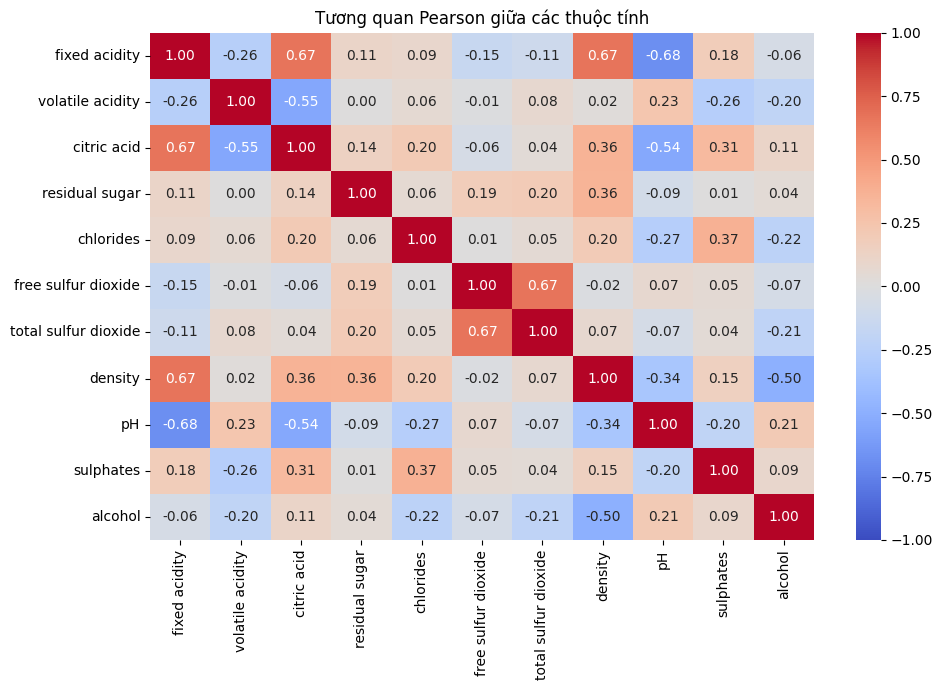

Các cột có thể loại vì tương quan rất cao: Không có


In [1]:
print("Họ tên: Nguyễn Đức Vinh | MSSV: 6451071087")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report)

# Khi chạy trên Colab, nếu chưa có file trong thư mục hiện tại, tự tải từ Drive công khai.
DATA_DIR = Path('data') if Path('data').exists() else Path('.')
DRIVE_IDS = {
    'adult.data.csv': '1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB',
    'adult.test.csv': '1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD',
    'winequality-red.csv': '1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH',
    'heart.csv': '10N9jGzMn-MagDWXORdP-qIpwC3omZJHb',
    'mushrooms.csv': '11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW',
    'test_image_Bai7.jpg': '1BH2qwN62GKZIHcF0kUi0N13YG2eex3wx'
}
def get_file(filename):
    p = DATA_DIR / filename
    if not p.exists():
        import subprocess, sys
        try:
            import gdown
        except ImportError:
            subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'gdown'])
            import gdown
        gdown.download(id=DRIVE_IDS[filename], output=str(p), quiet=False)
    if not p.exists():
        raise FileNotFoundError('Không tải được ' + filename + '. Hãy tải từ Drive và upload lên Colab.')
    return p

DATASET = 'wine'
data = pd.read_csv(get_file('winequality-red.csv'))
data = data.replace(r'^\s*\?\s*$', np.nan, regex=True).dropna().reset_index(drop=True)
print('Kích thước dữ liệu Wine:', data.shape)

# Pearson tính trên các cột số; không đưa nhãn quyết định vào phân tích tương quan thuộc tính.
numeric = data.drop(columns=['quality']).select_dtypes(include=np.number)
corr = numeric.corr(method='pearson')
print('Ma trận Pearson:')
print(corr.round(3).to_string())
plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Tương quan Pearson giữa các thuộc tính')
plt.tight_layout(); plt.show()
# Ngưỡng tham khảo |r| > 0.90, xét một nửa tam giác trên để tránh trùng lặp.
upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
drop_corr = [c for c in upper.columns if any(upper[c] > 0.90)]
print('Các cột có thể loại vì tương quan rất cao:', drop_corr if drop_corr else 'Không có')
